# MobileViT-XS — Waste Classification (Checkpoint 1)

Arsitektur: **MobileViT-XS** (Mehta & Rastegari, 2022, *MobileViT: Light-weight, General-purpose,
and Mobile-friendly Vision Transformer*, ICLR 2022, arXiv:2110.02178). Bobot ImageNet diambil dari
`timm` (`mobilevit_xs.cvnets_in1k`), karena `torchvision` belum menyediakannya.

Paper untuk dataset dan protokol training: Yong, L., Ma, L., Sun, D., & Du, L. (2023).
*Application of MobileNetV2 to waste classification.* PLOS ONE 18(3): e0282336.
<https://doi.org/10.1371/journal.pone.0282336>

Notebook ini menjalankan MobileViT-XS pada dataset, split, dan protokol yang sama dengan eksperimen
MobileNetV2, CNN, MobileNetV3-Small, MobileNetV3-Large, dan MobileNetV4-Conv-Small. Semua artefak
ditulis ke `outputs/` di root repository.

| | MobileNetV2 | MobileNetV3-Small | MobileNetV4-Conv-Small | MobileViT-XS |
|---|---|---|---|---|
| Sumber bobot | `torchvision` | `torchvision` | `timm` | `timm` |
| Parameter (1000 kelas) | 3,50 M | 2,54 M | 3,77 M | 2,33 M |
| GMACs @224 | 0,30 | 0,06 | 0,19 | 0,77 |
| ImageNet top-1 | 71,9% | 67,7% | 74,6% (256 px) | 74,8% (paper, 256 px) |

MobileViT-XS adalah kandidat dengan parameter paling sedikit di antara model yang performanya
setara MobileNetV2. Catatan penting: biaya komputasinya **lebih tinggi** (0,77 GMACs, sekitar 2,5x
MobileNetV2) karena blok transformer, jadi "ringan" di sini berarti kecil di penyimpanan, bukan
tercepat saat inference.

Implementasi `timm` (`mobilevit_xs.cvnets_in1k`) memakai bobot yang dilatih pada 256 px, sedangkan
notebook ini tetap 224 px supaya setara dengan model lain. Konsekuensinya angka ImageNet di tabel
bukan pembanding apples-to-apples, dan akurasi di dataset ini bisa sedikit di bawah potensinya.

Tiga varian resep training yang sama (baseline, cosine, augment) tetap dijalankan supaya hasilnya
bisa dibandingkan langsung dengan model lain.

## Daftar isi

1. Setup dan konfigurasi
2. Dataset dan split
3. Transform dan loader
4. Model MobileViT-XS
5. Training loop
6. Tiga varian training
7. Kurva training
8. Evaluasi test
9. Confusion matrix
10. Analisis error
11. Perbandingan dengan baseline
12. Simpan ringkasan

## 1. Setup dan konfigurasi

Hyperparameter dasar mengikuti `train_245_class.py` (SGD 0,001, momentum 0,9, StepLR 7/0,1,
50 epoch, batch 42) agar hasil MobileViT-XS sebanding dengan MobileNetV2, CNN, dan
MobileNetV3-Small.

Notebook ini memerlukan `timm`. Cell setup di bawah memasangnya otomatis bila belum ada, dan bobot
ImageNet `mobilevit_xs.cvnets_in1k` diunduh dari Hugging Face saat model pertama kali
dibuat, jadi butuh koneksi internet.

Tiga varian training dijalankan berurutan. Ketiganya memakai arsitektur, split, seed, transform
evaluasi, jumlah epoch, dan early stopping yang sama; hanya resep training yang berbeda. Semua
varian diekspor dengan prefix masing-masing.

In [1]:
# ---------------------------------------------------------------------------
# Auto-install dependencies. Packages that are already installed are untouched.
# ---------------------------------------------------------------------------
from __future__ import annotations

import importlib.util
import subprocess
import sys


def module_available(name: str) -> bool:
    return importlib.util.find_spec(name) is not None


def pip_install(*packages: str, index_url: str | None = None) -> bool:
    command = [sys.executable, "-m", "pip", "install", "-q"]
    if index_url:
        command += ["--index-url", index_url]
    command += list(packages)
    print("    $", " ".join(command))
    try:
        return subprocess.run(command, check=False).returncode == 0
    except Exception as exc:
        print(f"[warn] pip install failed for {' '.join(packages)}: {exc}")
        return False


def ensure(packages: dict[str, str]) -> list[str]:
    missing = [pkg for pkg, mod in packages.items() if not module_available(mod)]
    if not missing:
        return []
    print(f"[setup] installing: {', '.join(missing)}")
    for package in missing:
        pip_install(package)
    still_missing = [pkg for pkg in missing if not module_available(packages[pkg])]
    if still_missing:
        print("[warn] could not install: " + ", ".join(still_missing))
    return still_missing


ensure({
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "Pillow": "PIL",
    "tqdm": "tqdm",
    "ipywidgets": "ipywidgets",
    "timm": "timm",
})

if not module_available("torch") or not module_available("torchvision"):
    print("[setup] installing torch and torchvision")
    installed = pip_install(
        "torch", "torchvision", index_url="https://download.pytorch.org/whl/cpu"
    )
    if not installed and (not module_available("torch") or not module_available("torchvision")):
        print("[setup] retrying with the default PyPI index")
        pip_install("torch", "torchvision")

print("[setup] dependency check done")

[setup] dependency check done


In [2]:
from __future__ import annotations

import copy
import json
import math
import os
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
try:
    from ipywidgets import IProgress  # noqa: F401
    from tqdm.auto import tqdm
except Exception:
    from tqdm import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.unicode_minus": False,
})

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").is_dir() and (candidate / "Datasets").is_dir():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
OUTPUT_DIR = REPO_ROOT / "outputs"
SPLIT_DIR = OUTPUT_DIR / "splits"
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
for _d in (OUTPUT_DIR, SPLIT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(
    os.environ.get("TRASH_DATA_DIR", REPO_ROOT / "Datasets" / "images" / "images")
).resolve()

# Paper defaults from train_245_class.py, kept identical for a fair comparison.
IMG_SIZE = 224
BATCH_SIZE = 42
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
MOMENTUM = 0.9
STEP_SIZE = 7
GAMMA = 0.1
NUM_WORKERS = 0
PRETRAINED = os.environ.get("TRASH_REPRO_PRETRAINED", "1") == "1"

# MobileViT-XS hanya tersedia lewat timm. Bobot ImageNet: 3,77 M parameter,
# ImageNet top-1 74,6% pada test crop 256 (model card timm).
TIMM_MODEL_NAME = "mobilevit_xs.cvnets_in1k"
TEST_BATCH_SIZE = 128

# Early stopping: hentikan training jika validation accuracy tidak membaik.
EARLY_STOP_PATIENCE = 10
EARLY_STOP_MIN_EPOCHS = 10

QUICK_TEST = os.environ.get("TRASH_REPRO_QUICK", "0") == "1"
TRAIN_PER_CLASS = VAL_PER_CLASS = TEST_PER_CLASS = None
if QUICK_TEST:
    NUM_EPOCHS = 1
    BATCH_SIZE = 16
    PRETRAINED = False
    TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 20, 5, 5
    EARLY_STOP_PATIENCE = 3
    EARLY_STOP_MIN_EPOCHS = 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python           : {sys.version.split()[0]}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {DEVICE}")
print(f"Repo root        : {REPO_ROOT}")
print(f"Data root        : {DATA_ROOT} (exists={DATA_ROOT.exists()})")
print(f"Output folder    : {OUTPUT_DIR}")
print(f"Quick test       : {QUICK_TEST}")
print(f"Pretrained weights: {PRETRAINED}")
print(f"Backbone         : {TIMM_MODEL_NAME} (timm)")
print(f"Early stopping   : patience {EARLY_STOP_PATIENCE} epoch (min {EARLY_STOP_MIN_EPOCHS})")

Python           : 3.12.3
PyTorch          : 2.15.0+cu132
Device           : cuda
Repo root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16
Data root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/Datasets/images/images (exists=True)
Output folder    : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs
Quick test       : False
Pretrained weights: True
Backbone         : mobilevit_xs.cvnets_in1k (timm)
Early stopping   : patience 10 epoch (min 10)


## 2. Dataset dan split

Split 8:1:1 yang dipakai MobileNetV2 dan CNN dibaca ulang dari `outputs/splits/all.csv`
(stratified per kelas dan source group, seed 42). Dataset dan splitnya identik, jadi dedupe MD5
dan split tidak diulang di sini.

In [3]:
# ---------------------------------------------------------------------------
# 30 fine classes and the 3-class grouping used by the earlier experiments.
# ---------------------------------------------------------------------------
CLASS_NAMES = [
    "aerosol_cans",
    "aluminum_food_cans",
    "aluminum_soda_cans",
    "cardboard_boxes",
    "cardboard_packaging",
    "clothing",
    "coffee_grounds",
    "disposable_plastic_cutlery",
    "eggshells",
    "food_waste",
    "glass_beverage_bottles",
    "glass_cosmetic_containers",
    "glass_food_jars",
    "magazines",
    "newspaper",
    "office_paper",
    "paper_cups",
    "plastic_cup_lids",
    "plastic_detergent_bottles",
    "plastic_food_containers",
    "plastic_shopping_bags",
    "plastic_soda_bottles",
    "plastic_straws",
    "plastic_trash_bags",
    "plastic_water_bottles",
    "shoes",
    "steel_food_cans",
    "styrofoam_cups",
    "styrofoam_food_containers",
    "tea_bags",
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

MAJOR_NAMES = ["Kitchen waste", "Recyclable waste", "Other waste"]
MAJOR_TO_IDX = {name: i for i, name in enumerate(MAJOR_NAMES)}

CLASS_TO_MAJOR = {
    "coffee_grounds": "Kitchen waste",
    "eggshells": "Kitchen waste",
    "food_waste": "Kitchen waste",
    "tea_bags": "Kitchen waste",
    "aerosol_cans": "Recyclable waste",
    "aluminum_food_cans": "Recyclable waste",
    "aluminum_soda_cans": "Recyclable waste",
    "cardboard_boxes": "Recyclable waste",
    "cardboard_packaging": "Recyclable waste",
    "clothing": "Recyclable waste",
    "glass_beverage_bottles": "Recyclable waste",
    "glass_cosmetic_containers": "Recyclable waste",
    "glass_food_jars": "Recyclable waste",
    "magazines": "Recyclable waste",
    "newspaper": "Recyclable waste",
    "office_paper": "Recyclable waste",
    "paper_cups": "Recyclable waste",
    "plastic_detergent_bottles": "Recyclable waste",
    "plastic_food_containers": "Recyclable waste",
    "plastic_shopping_bags": "Recyclable waste",
    "plastic_soda_bottles": "Recyclable waste",
    "plastic_water_bottles": "Recyclable waste",
    "shoes": "Recyclable waste",
    "steel_food_cans": "Recyclable waste",
    "disposable_plastic_cutlery": "Other waste",
    "plastic_cup_lids": "Other waste",
    "plastic_straws": "Other waste",
    "plastic_trash_bags": "Other waste",
    "styrofoam_cups": "Other waste",
    "styrofoam_food_containers": "Other waste",
}

missing_mapping = sorted(set(CLASS_NAMES) - set(CLASS_TO_MAJOR))
assert not missing_mapping, f"Missing major-class mapping for: {missing_mapping}"

print(f"Classes: {NUM_CLASSES}")
print(pd.Series(CLASS_TO_MAJOR).value_counts().to_string())

Classes: 30
Recyclable waste    20
Other waste          6
Kitchen waste        4


In [4]:
assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}. Set TRASH_DATA_DIR."
missing_dirs = [name for name in CLASS_NAMES if not (DATA_ROOT / name).is_dir()]
assert not missing_dirs, f"Missing class folders under {DATA_ROOT}: {missing_dirs}"

SPLIT_MANIFEST = SPLIT_DIR / "all.csv"
if not SPLIT_MANIFEST.exists():
    raise FileNotFoundError(
        f"{SPLIT_MANIFEST} not found. Run the MobileNetV2 notebook once to write the manifest."
    )

df = pd.read_csv(SPLIT_MANIFEST)
df = df[["rel_path", "class_name", "source_group", "md5", "split", "label"]]
df["label"] = df["class_name"].map(CLASS_TO_IDX).astype(int)

if QUICK_TEST:
    limits = {"train": TRAIN_PER_CLASS, "val": VAL_PER_CLASS, "test": TEST_PER_CLASS}
    parts = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        n_total = limits[split_name]
        n_groups = max(1, group["source_group"].nunique())
        n_per_group = max(1, math.ceil(n_total / n_groups))
        for _source_group, subgroup in group.groupby("source_group", sort=True):
            parts.append(subgroup.head(n_per_group))
    df = pd.concat(parts, ignore_index=True)
    trimmed = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        trimmed.append(group.head(limits[split_name]))
    df = pd.concat(trimmed, ignore_index=True)

df = df.sort_values(["split", "class_name", "rel_path"]).reset_index(drop=True)

print("Split sizes:")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
assert set(df["split"]) == {"train", "val", "test"}
assert df.groupby("split")["class_name"].nunique().eq(NUM_CLASSES).all()
assert df.groupby("md5")["split"].nunique().eq(1).all(), "Duplicate image crossed a split."

Split sizes:
split
train    9006
val      1124
test     1133


## 3. Transform dan loader

In [5]:
# Normalisasi dan resize mengikuti config bobot pretrained timm, bukan asumsi ImageNet.
# Contoh: ra4 memakai mean/std 0,5 dan crop_pct 0,95; MobileViT memakai input [0, 1].
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
EVAL_RESIZE = 256
try:
    import timm as _timm

    _data_cfg = _timm.data.resolve_model_data_config(
        _timm.create_model(TIMM_MODEL_NAME, pretrained=False)
    )
    IMAGENET_MEAN = [float(v) for v in _data_cfg["mean"]]
    IMAGENET_STD = [float(v) for v in _data_cfg["std"]]
    EVAL_RESIZE = int(round(IMG_SIZE / _data_cfg["crop_pct"]))
except Exception as _exc:  # timm belum terpasang: pakai ImageNet standar
    print(f"Info             : config bobot tidak terbaca ({_exc}); pakai ImageNet standar")

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(EVAL_RESIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class TrashDataset(Dataset):
    '''Manifest-backed image dataset for the Kaggle waste folder layout.'''

    def __init__(self, frame: pd.DataFrame, root: Path, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["rel_path"]) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(
    frame: pd.DataFrame, training: bool, batch_size: int, transform=None
) -> DataLoader:
    dataset = TrashDataset(
        frame,
        DATA_ROOT,
        transform=transform if transform is not None else (
            train_transform if training else eval_transform
        ),
    )
    # BatchNorm needs more than one value per channel.
    drop_last = (
        training and len(dataset) >= batch_size and len(dataset) % batch_size == 1
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=drop_last,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker,
        generator=generator,
    )


train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

train_loader = make_loader(train_df, training=True, batch_size=BATCH_SIZE)
val_loader = make_loader(val_df, training=False, batch_size=BATCH_SIZE)
test_loader = make_loader(test_df, training=False, batch_size=TEST_BATCH_SIZE)

print(f"Normalisasi      : mean {IMAGENET_MEAN}, std {IMAGENET_STD}")
print(f"Eval resize      : {EVAL_RESIZE} px, crop {IMG_SIZE} px")
print(f"Train: {len(train_df):,} images, {len(train_loader)} batches")
print(f"Val  : {len(val_df):,} images, {len(val_loader)} batches")
print(f"Test : {len(test_df):,} images, {len(test_loader)} batches")

images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape))
print("Label range:", int(labels.min()), "..", int(labels.max()))

Normalisasi      : mean [0.0, 0.0, 0.0], std [1.0, 1.0, 1.0]
Eval resize      : 249 px, crop 224 px
Train: 9,006 images, 215 batches
Val  : 1,124 images, 27 batches
Test : 1,133 images, 9 batches


Batch shape: (42, 3, 224, 224)
Label range: 1 .. 29


## 4. Model MobileViT-XS

Model diambil dari `timm`, karena `torchvision` belum punya MobileNetV4. Head klasifikasi diganti
langsung lewat `num_classes=NUM_CLASSES`, jadi tidak perlu menebak indeks layer seperti pada
MobileNetV3 (`classifier[3]`).

Arsitektur, split, seed, dan protokol evaluasi sama untuk semua varian. Yang berbeda hanya resep
training.

In [6]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def measure_gmacs(model: nn.Module, size: int = IMG_SIZE) -> float:
    """GMACs untuk satu gambar, diukur dari satu forward pass."""
    from torch.utils.flop_counter import FlopCounterMode

    model.eval()
    counter = FlopCounterMode(display=False)
    with counter, torch.no_grad():
        model(torch.zeros(1, 3, size, size, device=DEVICE))
    return counter.get_total_flops() / 2 / 1e9


try:
    import timm
except ModuleNotFoundError:  # pesan jelas muncul di build_model()
    timm = None


def build_model(num_classes: int, pretrained: bool = True) -> nn.Module:
    """MobileViT-XS dari timm, head diganti untuk `num_classes` kelas."""
    if timm is None:
        raise RuntimeError(
            "timm tidak tersedia. Jalankan ulang cell setup, atau `pip install timm`, "
            "lalu restart kernel."
        )
    return timm.create_model(TIMM_MODEL_NAME, pretrained=pretrained, num_classes=num_classes)


def assert_pretrained_loaded(build, num_classes: int) -> nn.Module:
    """Pastikan bobot ImageNet benar-benar masuk, bukan training dari nol."""
    torch.manual_seed(SEED)
    probe = build(num_classes, pretrained=False)
    before = {
        name: tensor.clone()
        for name, tensor in probe.state_dict().items()
        if "classifier" not in name and "head" not in name
    }
    del probe
    model = build(num_classes, pretrained=True)
    state = model.state_dict()
    changed = sum(1 for name, tensor in before.items() if not torch.equal(tensor, state[name]))
    if changed < 0.9 * len(before):
        raise RuntimeError(
            f"Bobot pretrained tidak termuat: hanya {changed}/{len(before)} tensor backbone "
            "berubah dari inisialisasi acak. Cek koneksi internet lalu ulangi cell ini."
        )
    print(f"Bobot pretrained : termuat ({changed}/{len(before)} tensor backbone berubah)")
    return model

_probe = build_model(NUM_CLASSES, pretrained=False)
print(f"timm             : {getattr(timm, '__version__', 'unknown')}")
print(f"Bobot            : {TIMM_MODEL_NAME}")
print(f"Parameter        : {count_parameters(_probe) / 1e6:.2f} M")
_resolve_cfg = getattr(timm.data, "resolve_model_data_config", None)
if _resolve_cfg is not None:
    for _key, _value in _resolve_cfg(_probe).items():
        if _key in ("input_size", "mean", "std", "crop_pct", "interpolation"):
            print(f"  data config {_key:14s}: {_value}")
del _probe
if PRETRAINED:
    _loaded = assert_pretrained_loaded(build_model, NUM_CLASSES)
    print(f"  pretrained_cfg : {_loaded.pretrained_cfg.get('hf_hub_id', '-')}")
else:
    print("Bobot pretrained : dilewati (PRETRAINED=False)")
print(
    f"Eval transform   : Resize(256) + CenterCrop({IMG_SIZE}) + ImageNet normalization "
    "(identik dengan MobileNetV3-Small)"
)

timm             : 1.0.31
Bobot            : mobilevit_xs.cvnets_in1k
Parameter        : 1.94 M
  data config input_size    : (3, 256, 256)
  data config interpolation : bicubic
  data config mean          : (0.0, 0.0, 0.0)
  data config std           : (1.0, 1.0, 1.0)
  data config crop_pct      : 0.9


model.safetensors: reconstructing file:   0%|          |  0.00B / 9.34MB            

model.safetensors: downloading bytes:           |  0.00B            

Bobot pretrained : termuat (309/309 tensor backbone berubah)
  pretrained_cfg : timm/mobilevit_xs.cvnets_in1k
Eval transform   : Resize(256) + CenterCrop(224) + ImageNet normalization (identik dengan MobileNetV3-Small)


## 5. Training loop

Epoch terbaik dipilih berdasarkan **validation accuracy**. Early stopping aktif: training berhenti
jika validation accuracy tidak membaik selama `EARLY_STOP_PATIENCE` epoch setelah
`EARLY_STOP_MIN_EPOCHS` epoch. Bobot terbaik tetap dipulihkan sebelum evaluasi.

In [7]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs,
    device,
    checkpoint_path,
    history_path,
    model_name,
    arch,
    extra_config=None,
    full_model_path=None,
    early_stopping_patience=None,
    early_stop_min_epochs=0,
):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    stopped_epoch = 0
    history = []
    dataloaders = {"train": train_loader, "val": val_loader}
    dataset_sizes = {phase: len(loader.dataset) for phase, loader in dataloaders.items()}

    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}")
        print("-" * 10)
        epoch_start = time.time()
        epoch_losses = {}
        epoch_accs = {}
        improved_this_epoch = False

        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()

            running_loss = 0.0
            running_corrects = 0
            loader = dataloaders[phase]

            progress = tqdm(
                total=dataset_sizes[phase],
                desc=f"{model_name} {phase} {epoch}/{epochs}",
                leave=False,
            )
            for inputs, labels in loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                progress.update(inputs.size(0))
            progress.close()

            if phase == "train" and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            epoch_losses[phase] = float(epoch_loss)
            epoch_accs[phase] = float(epoch_acc)
            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == "val" and epoch_acc > best_val_acc:
                best_val_acc = float(epoch_acc)
                best_epoch = epoch
                improved_this_epoch = True
                best_model_wts = copy.deepcopy(model.state_dict())
                checkpoint = {
                    "arch": arch,
                    "model_name": model_name,
                    "state_dict": model.state_dict(),
                    "class_names": CLASS_NAMES,
                    "major_names": MAJOR_NAMES,
                    "class_to_major": CLASS_TO_MAJOR,
                    "img_size": IMG_SIZE,
                    "mean": IMAGENET_MEAN,
                    "std": IMAGENET_STD,
                    "epoch": epoch,
                    "val_acc": float(epoch_acc),
                    "val_loss": float(epoch_loss),
                    "config": {
                        "seed": SEED,
                        "batch_size": BATCH_SIZE,
                        "epochs": epochs,
                        "pretrained": PRETRAINED,
                        **(extra_config or {}),
                    },
                }
                torch.save(checkpoint, checkpoint_path)

        if improved_this_epoch:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]
        record = {
            "epoch": epoch,
            "train_loss": epoch_losses["train"],
            "train_acc": epoch_accs["train"],
            "val_loss": epoch_losses["val"],
            "val_acc": epoch_accs["val"],
            "lr": float(current_lr),
            "time_sec": float(time.time() - epoch_start),
            "best_val_acc": best_val_acc,
        }
        history.append(record)
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"[{model_name}] epoch {epoch:02d}/{epochs} | "
            f"train loss {record['train_loss']:.4f} acc {record['train_acc']:.4f} | "
            f"val loss {record['val_loss']:.4f} acc {record['val_acc']:.4f} | "
            f"lr {current_lr:.2e} | {record['time_sec']:.1f}s"
        )
        print()

        if (
            early_stopping_patience is not None
            and epoch >= early_stop_min_epochs
            and epochs_without_improvement >= early_stopping_patience
        ):
            stopped_epoch = epoch
            print(
                f"Early stopping at epoch {epoch}: validation accuracy tidak membaik "
                f"selama {early_stopping_patience} epoch."
            )
            break

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Epochs run: {len(history)}/{epochs}")
    if stopped_epoch:
        print(f"Stopped early at epoch {stopped_epoch}")
    print(f"Best val Acc: {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(best_model_wts)
    if full_model_path is not None:
        torch.save(model, full_model_path)
        print(f"Full model: {full_model_path}")
    print(f"Checkpoint: {checkpoint_path}")
    return history, best_val_acc, best_epoch


def load_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=device)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)

## 6. Tiga varian training

| Varian | Prefix artefak | Perubahan |
|---|---|---|
| A · baseline | `mobilevitxs_` | StepLR 7/0,1, tanpa weight decay, cross-entropy biasa |
| B · cosine | `mobilevitxs_cosine_` | label smoothing 0,1, weight decay 1e-4, cosine annealing |
| C · augment | `mobilevitxs_aug_` | RandomResizedCrop 0,7–1,0, ColorJitter ringan, RandomErasing p=0,1 |

Split, seed, arsitektur, jumlah epoch, dan early stopping identik. Semua varian diekspor.

Varian C memakai augmentasi ringan: TrivialAugmentWide dan class weight dihapus karena pada 9.006
gambar latih keduanya menurunkan akurasi maupun macro F1 pada percobaan MobileNetV3-Small
(cardboard_boxes −25,6 poin).

Bobot pretrained diverifikasi saat model dibangun: kalau kurang dari 90% tensor backbone berubah
dari inisialisasi acak, cell 4 berhenti dengan `RuntimeError` alih-alih melatih dari nol.

In [8]:
aug_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.1)),
])

VARIANTS = {
    "mobilevitxs": {
        "label": "A · baseline",
        "transform": train_transform,
        "augmentation": "randomresizedcrop+flip",
        "label_smoothing": 0.0,
        "weight_decay": 0.0,
        "scheduler": "step",
    },
    "mobilevitxs_cosine": {
        "label": "B · cosine",
        "transform": train_transform,
        "augmentation": "randomresizedcrop+flip",
        "label_smoothing": 0.1,
        "weight_decay": 1e-4,
        "scheduler": "cosine",
    },
    "mobilevitxs_aug": {
        "label": "C · augment",
        "transform": aug_train_transform,
        "augmentation": "rrc(0.7-1.0)+flip+colorjitter+erasing",
        "label_smoothing": 0.0,
        "weight_decay": 0.0,
        "scheduler": "step",
    },
}


def build_criterion(spec):
    return nn.CrossEntropyLoss(label_smoothing=spec["label_smoothing"])


def build_scheduler(optimizer, spec, epochs):
    if spec["scheduler"] == "cosine":
        return lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)


for name, spec in VARIANTS.items():
    print(f"{name:26s} | {spec['label']:12s} | scheduler={spec['scheduler']:6s} "
          f"| ls={spec['label_smoothing']} | wd={spec['weight_decay']} "
          f"| augment={spec['augmentation']}")


mobilevitxs                | A · baseline | scheduler=step   | ls=0.0 | wd=0.0 | augment=randomresizedcrop+flip
mobilevitxs_cosine         | B · cosine   | scheduler=cosine | ls=0.1 | wd=0.0001 | augment=randomresizedcrop+flip
mobilevitxs_aug            | C · augment  | scheduler=step   | ls=0.0 | wd=0.0 | augment=rrc(0.7-1.0)+flip+colorjitter+erasing


In [9]:
runs = {}

for name, spec in VARIANTS.items():
    print("=" * 78)
    print(f"Training {name} ({spec['label']})")
    print("=" * 78)

    variant_train_loader = make_loader(
        train_df, training=True, batch_size=BATCH_SIZE, transform=spec["transform"]
    )
    variant_model = build_model(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)
    variant_criterion = build_criterion(spec)
    variant_optimizer = optim.SGD(
        variant_model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=spec["weight_decay"],
    )
    variant_scheduler = build_scheduler(variant_optimizer, spec, NUM_EPOCHS)

    checkpoint_path = MODEL_DIR / f"{name}_trash30_best.pt"
    full_model_path = MODEL_DIR / f"{name}_trash30_full.pt"
    history_path = RESULT_DIR / f"{name}_history.csv"

    variant_history, variant_best_acc, variant_best_epoch = train_model(
        model=variant_model,
        train_loader=variant_train_loader,
        val_loader=val_loader,
        criterion=variant_criterion,
        optimizer=variant_optimizer,
        scheduler=variant_scheduler,
        epochs=NUM_EPOCHS,
        device=DEVICE,
        checkpoint_path=checkpoint_path,
        full_model_path=full_model_path,
        history_path=history_path,
        model_name=name,
        arch="mobilevit_xs",
        extra_config={
            "variant": spec["label"],
            "learning_rate": LEARNING_RATE,
            "momentum": MOMENTUM,
            "weight_decay": spec["weight_decay"],
            "label_smoothing": spec["label_smoothing"],
            "scheduler": spec["scheduler"],
            "augmentation": spec["augmentation"],
        },
        early_stopping_patience=EARLY_STOP_PATIENCE,
        early_stop_min_epochs=EARLY_STOP_MIN_EPOCHS,
    )

    runs[name] = {
        "label": spec["label"],
        "spec": spec,
        "model": variant_model,
        "history": variant_history,
        "best_val_acc": variant_best_acc,
        "best_epoch": variant_best_epoch,
        "checkpoint": checkpoint_path,
        "full_model": full_model_path,
        "history_csv": history_path,
    }
    print(f"{name}: best val acc {variant_best_acc:.4f} @ epoch {variant_best_epoch}")

print("\nSelesai:", ", ".join(runs))

Training mobilevitxs (A · baseline)


Epoch 1/50
----------


mobilevitxs train 1/50:   0%|                                                                                                                                    | 0/9006 [00:00<?, ?it/s]

mobilevitxs train 1/50:   0%|▌                                                                                                                          | 42/9006 [00:00<03:13, 46.32it/s]

mobilevitxs train 1/50:   1%|█▏                                                                                                                         | 84/9006 [00:01<01:50, 80.53it/s]

mobilevitxs train 1/50:   1%|█▋                                                                                                                       | 126/9006 [00:01<01:23, 106.26it/s]

... (30,990 outputs left out)

mobilevitxs_aug val 36/50:  93%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████▎       | 1050/1124 [00:03<00:00, 292.59it/s]

mobilevitxs_aug val 36/50:  97%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋   | 1092/1124 [00:03<00:00, 291.93it/s]

mobilevitxs_aug val 36/50: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1124/1124 [00:03<00:00, 293.04it/s]

val Loss: 0.9906 Acc: 0.7198
[mobilevitxs_aug] epoch 36/50 | train loss 1.0071 acc 0.7316 | val loss 0.9906 acc 0.7198 | lr 1.00e-08 | 73.0s

Early stopping at epoch 36: validation accuracy tidak membaik selama 10 epoch.
Training complete in 43m 44s
Epochs run: 36/50
Stopped early at epoch 36
Best val Acc: 0.7304 at epoch 26
Full model: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilevitxs_aug_trash30_full.pt
Checkpoint: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilevitxs_aug_trash30_best.pt
mobilevitxs_aug: best val acc 0.7304 @ epoch 26

Selesai: mobilevitxs, mobilevitxs_cosine, mobilevitxs_aug


## 7. Kurva training

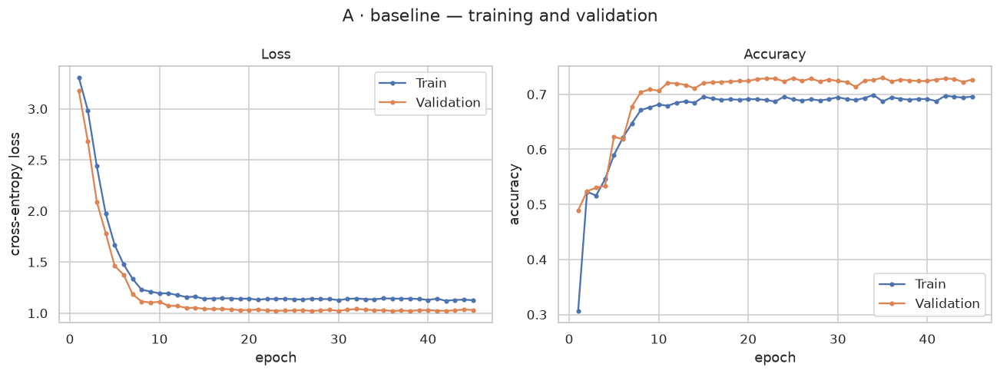

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
40,41,1.141078,0.687653,1.023978,0.726868,1.000000e-08,57.097908,0.730427
41,42,1.120718,0.697424,1.022562,0.728648,1.000000e-09,56.827153,0.730427
42,43,1.128871,0.695425,1.026702,0.727758,1.000000e-09,56.804005,0.730427
43,44,1.131524,0.693982,1.035203,0.722420,1.000000e-09,58.445238,0.730427
44,45,1.126144,0.695980,1.029481,0.726868,1.000000e-09,58.289136,0.730427


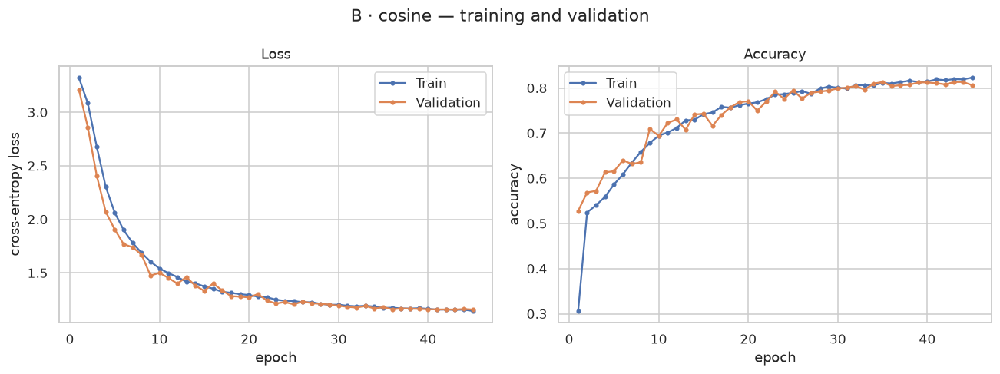

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
40,41,1.156414,0.818899,1.158635,0.810498,0.000078,57.593328,0.813167
41,42,1.157659,0.817233,1.158077,0.807829,0.000062,57.522452,0.813167
42,43,1.154798,0.819676,1.157633,0.813167,0.000048,57.387915,0.813167
43,44,1.156600,0.819010,1.162150,0.813167,0.000035,57.489942,0.813167
44,45,1.143970,0.823007,1.157806,0.806050,0.000024,57.468838,0.813167


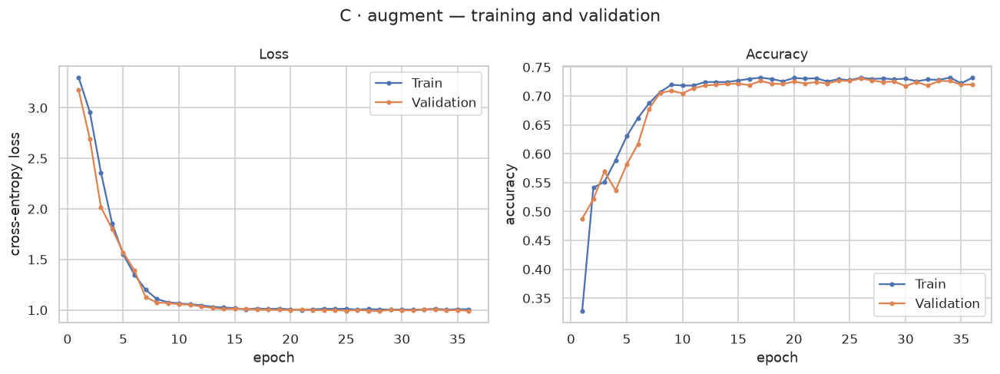

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
31,32,1.005219,0.728625,1.006963,0.717972,1.000000e-07,72.784383,0.730427
32,33,1.011593,0.727959,1.005437,0.725979,1.000000e-07,72.775152,0.730427
33,34,1.002137,0.731956,0.996625,0.725979,1.000000e-07,72.816691,0.730427
34,35,1.007436,0.721963,0.999114,0.719751,1.000000e-08,72.640241,0.730427
35,36,1.007073,0.731623,0.990564,0.719751,1.000000e-08,73.019054,0.730427


In [10]:
def plot_training_curves(history, title: str, output_path: Path):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", ms=3, label="Train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", ms=3, label="Validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title("Loss")
    axes[0].legend()

    axes[1].plot(frame["epoch"], frame["train_acc"], marker="o", ms=3, label="Train")
    axes[1].plot(frame["epoch"], frame["val_acc"], marker="o", ms=3, label="Validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].set_title("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


for name, run in runs.items():
    plot_training_curves(
        run["history"],
        f"{run['label']} — training and validation",
        FIGURE_DIR / f"{name}_curves.png",
    )
    display(pd.DataFrame(run["history"]).tail())

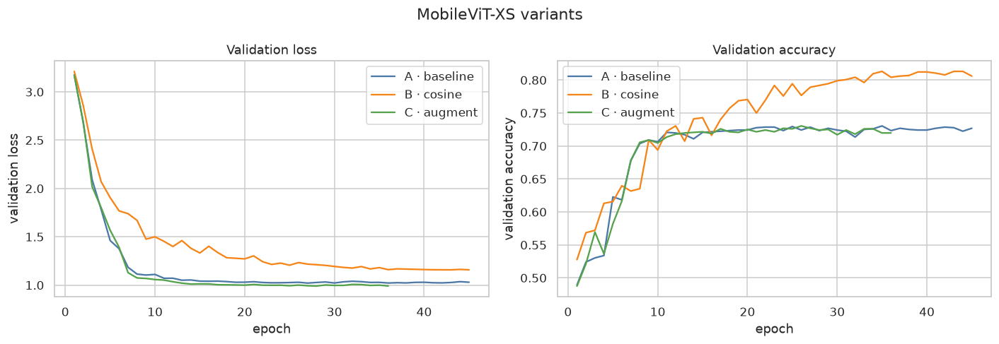

In [11]:
variant_colors = {"mobilevitxs": "#4C78A8",
                  "mobilevitxs_cosine": "#F58518",
                  "mobilevitxs_aug": "#54A24B"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, run in runs.items():
    frame = pd.DataFrame(run["history"])
    axes[0].plot(frame["epoch"], frame["val_loss"],
                 label=run["label"], color=variant_colors[name])
    axes[1].plot(frame["epoch"], frame["val_acc"],
                 label=run["label"], color=variant_colors[name])

axes[0].set_xlabel("epoch")
axes[0].set_ylabel("validation loss")
axes[0].set_title("Validation loss")
axes[0].legend()
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
axes[1].set_title("Validation accuracy")
axes[1].legend()

fig.suptitle("MobileViT-XS variants")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mobilevitxs_variants_curves.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. Evaluasi test

In [12]:
def jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def aggregate_major_probs(probs: np.ndarray, class_names):
    major_probs = np.zeros((probs.shape[0], len(MAJOR_NAMES)), dtype=np.float64)
    for class_idx, class_name in enumerate(class_names):
        major_probs[:, MAJOR_TO_IDX[CLASS_TO_MAJOR[class_name]]] += probs[:, class_idx]
    return major_probs


@torch.no_grad()
def predict_loader(model, loader, criterion, device):
    model.eval()
    all_probs, all_labels = [], []
    total_loss = 0.0
    total_samples = 0

    for images, labels in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    if total_samples == 0:
        raise RuntimeError("Empty evaluation loader.")
    probs = np.concatenate(all_probs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return probs, labels, total_loss / total_samples


def plot_confusion_matrix(cm, labels, title, output_path, normalize=True):
    cm = np.asarray(cm, dtype=np.float64)
    if normalize:
        row_sums = cm.sum(axis=1, keepdims=True)
        plot_cm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)
        fmt = ".2f"
    else:
        plot_cm = cm
        fmt = "d"

    annot = len(labels) <= 12
    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 0.48), max(6, len(labels) * 0.42)))
    sns.heatmap(
        plot_cm,
        annot=annot,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        cbar=True,
        linewidths=0.2 if annot else 0,
        annot_kws={"fontsize": 9} if annot else None,
    )
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def evaluate_and_save(model, loader, criterion, device, frame, model_key):
    probs, labels, loss = predict_loader(model, loader, criterion, device)
    preds = probs.argmax(axis=1)

    report_dict = classification_report(
        labels,
        preds,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(labels, preds, labels=np.arange(NUM_CLASSES))
    per_class_acc = np.divide(
        cm.diagonal(),
        cm.sum(axis=1),
        out=np.zeros(NUM_CLASSES, dtype=np.float64),
        where=cm.sum(axis=1) != 0,
    )

    major_probs = aggregate_major_probs(probs, CLASS_NAMES)
    major_true = frame["class_name"].map(lambda c: MAJOR_TO_IDX[CLASS_TO_MAJOR[c]]).to_numpy()
    major_pred = np.array([
        MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(index)]]] for index in preds
    ])
    major_prob_pred = major_probs.argmax(axis=1)
    major_report = classification_report(
        major_true,
        major_pred,
        labels=np.arange(len(MAJOR_NAMES)),
        target_names=MAJOR_NAMES,
        output_dict=True,
        zero_division=0,
    )
    major_cm = confusion_matrix(major_true, major_pred, labels=np.arange(len(MAJOR_NAMES)))

    prediction_frame = frame[["rel_path", "class_name", "source_group"]].copy()
    prediction_frame["true_label"] = labels
    prediction_frame["pred_label"] = preds
    prediction_frame["pred_class"] = [CLASS_NAMES[i] for i in preds]
    prediction_frame["confidence"] = probs.max(axis=1)
    prediction_frame["correct"] = (labels == preds).astype(int)
    for class_idx, class_name in enumerate(CLASS_NAMES):
        prediction_frame[f"prob_{class_name}"] = probs[:, class_idx]
    prediction_frame.to_csv(RESULT_DIR / f"{model_key}_predictions.csv", index=False)

    metrics = {
        "model": model_key,
        "split": "test",
        "num_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "loss": float(loss),
        "top3_accuracy": float(
            top_k_accuracy_score(
                labels,
                probs,
                k=min(3, NUM_CLASSES),
                labels=np.arange(NUM_CLASSES),
            )
        ),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class_accuracy": {
            name: float(per_class_acc[i]) for i, name in enumerate(CLASS_NAMES)
        },
        "group_accuracy": {
            str(group): float(sub["correct"].mean())
            for group, sub in prediction_frame.groupby("source_group")
        },
        "classification_report": report_dict,
        "confusion_matrix": cm.tolist(),
        "major_accuracy": float(accuracy_score(major_true, major_pred)),
        "major_prob_accuracy": float(accuracy_score(major_true, major_prob_pred)),
        "major_report": major_report,
        "major_confusion_matrix": major_cm.tolist(),
        "major_class_names": MAJOR_NAMES,
        "class_names": CLASS_NAMES,
    }
    with open(RESULT_DIR / f"{model_key}_metrics.json", "w") as handle:
        json.dump(jsonable(metrics), handle, indent=2)

    pd.DataFrame(report_dict).T.to_csv(RESULT_DIR / f"{model_key}_classification_report.csv")
    pd.DataFrame(major_report).T.to_csv(RESULT_DIR / f"{model_key}_major_report.csv")
    pd.DataFrame(
        per_class_acc, index=CLASS_NAMES, columns=["accuracy"]
    ).to_csv(RESULT_DIR / f"{model_key}_per_class_accuracy.csv")

    print(f"\n{model_key} — test results")
    print(f"  loss              : {metrics['loss']:.4f}")
    print(f"  30-class accuracy : {metrics['accuracy'] * 100:.2f}%")
    print(f"  macro F1 (30)     : {metrics['macro_f1']:.4f}")
    print(f"  top-3 accuracy    : {metrics['top3_accuracy'] * 100:.2f}%")
    print(f"  3-class accuracy  : {metrics['major_accuracy'] * 100:.2f}% (top-1 prefix)")
    print(f"  3-class prob agg  : {metrics['major_prob_accuracy'] * 100:.2f}%")
    print("  accuracy by source group:")
    for group, value in metrics["group_accuracy"].items():
        print(f"    {group:10s}: {value * 100:.2f}%")

    return metrics, probs, labels, preds, major_true, major_pred

In [13]:
eval_criterion = nn.CrossEntropyLoss()
evaluations = {}

for name, run in runs.items():
    eval_model = build_model(NUM_CLASSES, pretrained=False).to(DEVICE)
    ckpt = load_checkpoint(run["checkpoint"], DEVICE)
    eval_model.load_state_dict(ckpt["state_dict"])
    eval_model.eval()
    print(f"\n{name}: checkpoint epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")

    (
        metrics,
        test_probs,
        test_labels,
        test_preds,
        major_true,
        major_pred,
    ) = evaluate_and_save(
        eval_model, test_loader, eval_criterion, DEVICE, test_df, model_key=name
    )

    evaluations[name] = {
        "metrics": metrics,
        "model": eval_model,
        "gmacs": measure_gmacs(eval_model),
        "probabilities": test_probs,
        "labels": test_labels,
        "predictions": test_preds,
    }
    display(pd.DataFrame(metrics["major_report"]).T.round(3))


mobilevitxs: checkpoint epoch 35 (val acc 0.7304)


Evaluating:   0%|                                                                                                                                                   | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|███████████████▍                                                                                                                           | 1/9 [00:00<00:04,  1.79it/s]

Evaluating:  22%|██████████████████████████████▉                                                                                                            | 2/9 [00:01<00:03,  1.93it/s]

Evaluating:  33%|██████████████████████████████████████████████▎                                                                                            | 3/9 [00:01<00:02,  2.09it/s]

Evaluating:  44%|█████████████████████████████████████████████████████████████▊                                                                             | 4/9 [00:01<00:02,  2.17it/s]

... (29 outputs left out)

Evaluating:  89%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌               | 8/9 [00:03<00:00,  2.31it/s]

Evaluating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:03<00:00,  2.44it/s]


mobilevitxs_aug — test results
  loss              : 0.9265
  30-class accuracy : 75.29%
  macro F1 (30)     : 0.7259
  top-3 accuracy    : 92.85%
  3-class accuracy  : 93.03% (top-1 prefix)
  3-class prob agg  : 91.62%
  accuracy by source group:
    default   : 78.75%
    real_world: 69.56%


,precision,recall,f1-score,support
Kitchen waste,0.935,0.884,0.909,147.00
Recyclable waste,0.944,0.958,0.951,767.00
Other waste,0.879,0.863,0.871,219.00
accuracy,0.930,0.930,0.930,0.93
macro avg,0.919,0.902,0.910,1133.00
weighted avg,0.930,0.930,0.930,1133.00


In [14]:
insight_rows = []
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    insight_rows.append({
        "Varian": runs[name]["label"],
        "Prefix": name,
        "Test accuracy (%)": metric["accuracy"] * 100,
        "Cross-entropy loss": metric["loss"],
        "Top-3 accuracy (%)": metric["top3_accuracy"] * 100,
        "3-class accuracy (%)": metric["major_accuracy"] * 100,
        "3-class prob accuracy (%)": metric["major_prob_accuracy"] * 100,
        "Macro F1 (30 kelas)": metric["macro_f1"],
        "Macro F1 (3 major class)": metric["major_report"]["macro avg"]["f1-score"],
        "Parameters (M)": count_parameters(evaluation["model"]) / 1e6,
        "GMACs": evaluation["gmacs"],
    })

variant_table = pd.DataFrame(insight_rows).set_index("Varian")
display(variant_table.round(3))
variant_table.to_csv(RESULT_DIR / "mobilevitxs_variants_metrics.csv")

,Prefix,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M),GMACs
Varian,,,,,,,,,,
A · baseline,mobilevitxs,73.963,0.957,92.586,91.527,90.644,0.710,0.893,1.944,0.772
B · cosine,mobilevitxs_cosine,83.583,0.619,96.028,95.587,95.057,0.820,0.941,1.944,0.772
C · augment,mobilevitxs_aug,75.287,0.926,92.851,93.027,91.615,0.726,0.910,1.944,0.772


## 9. Confusion matrix

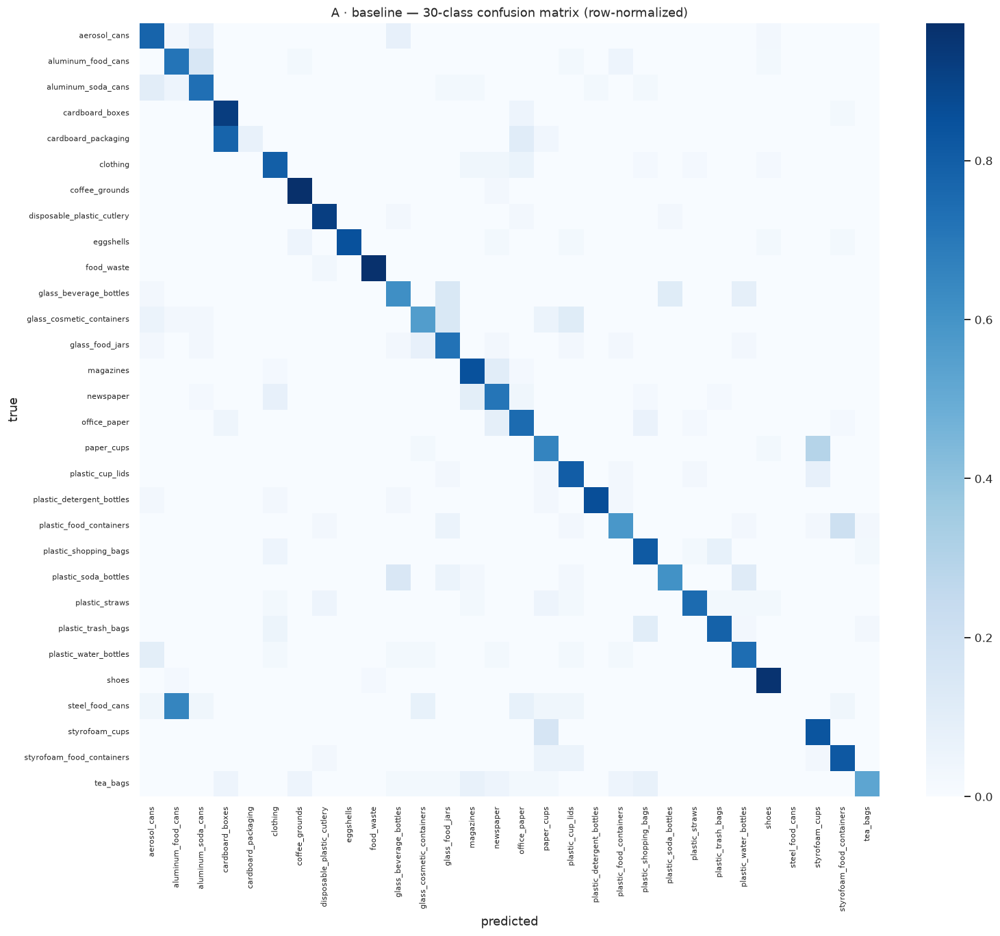

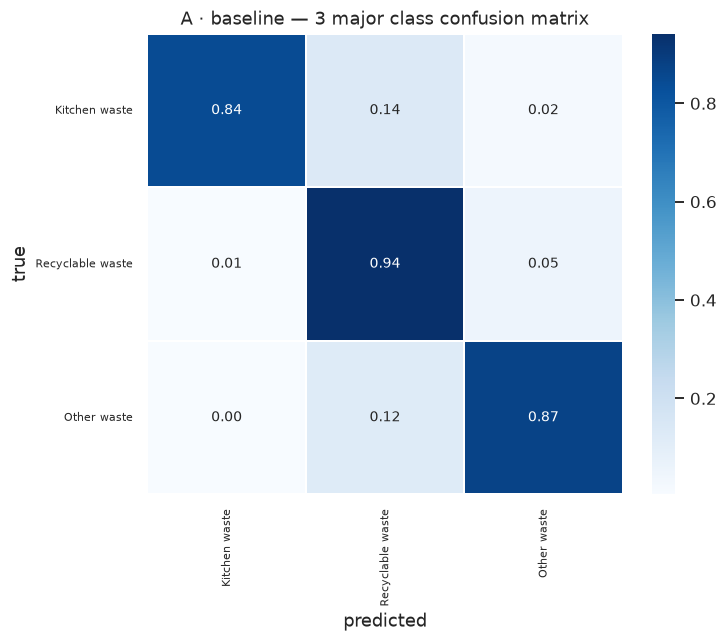

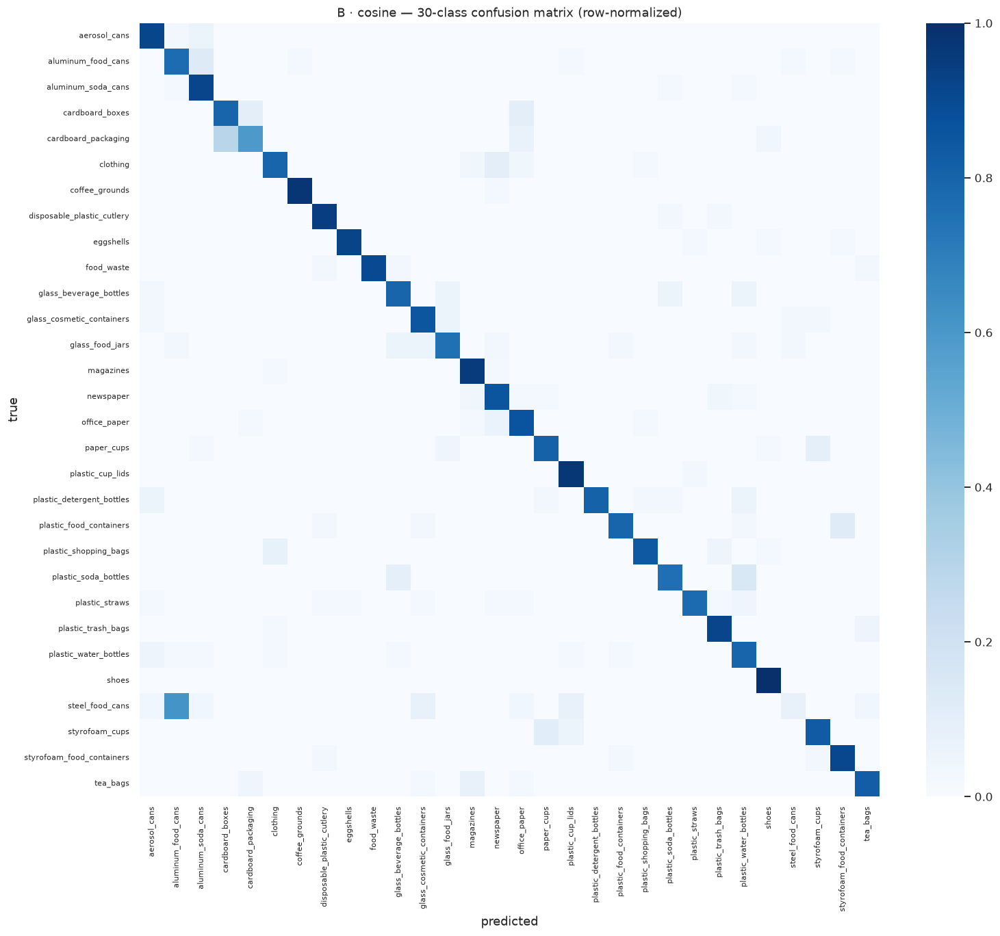

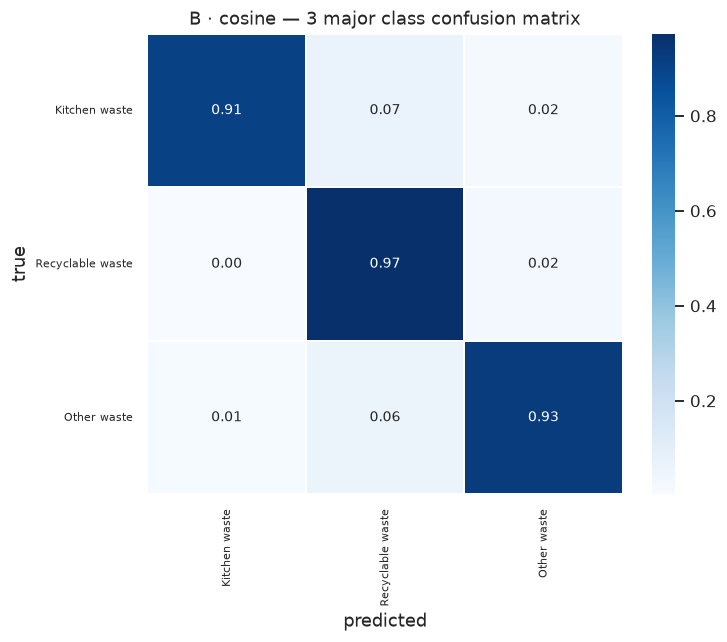

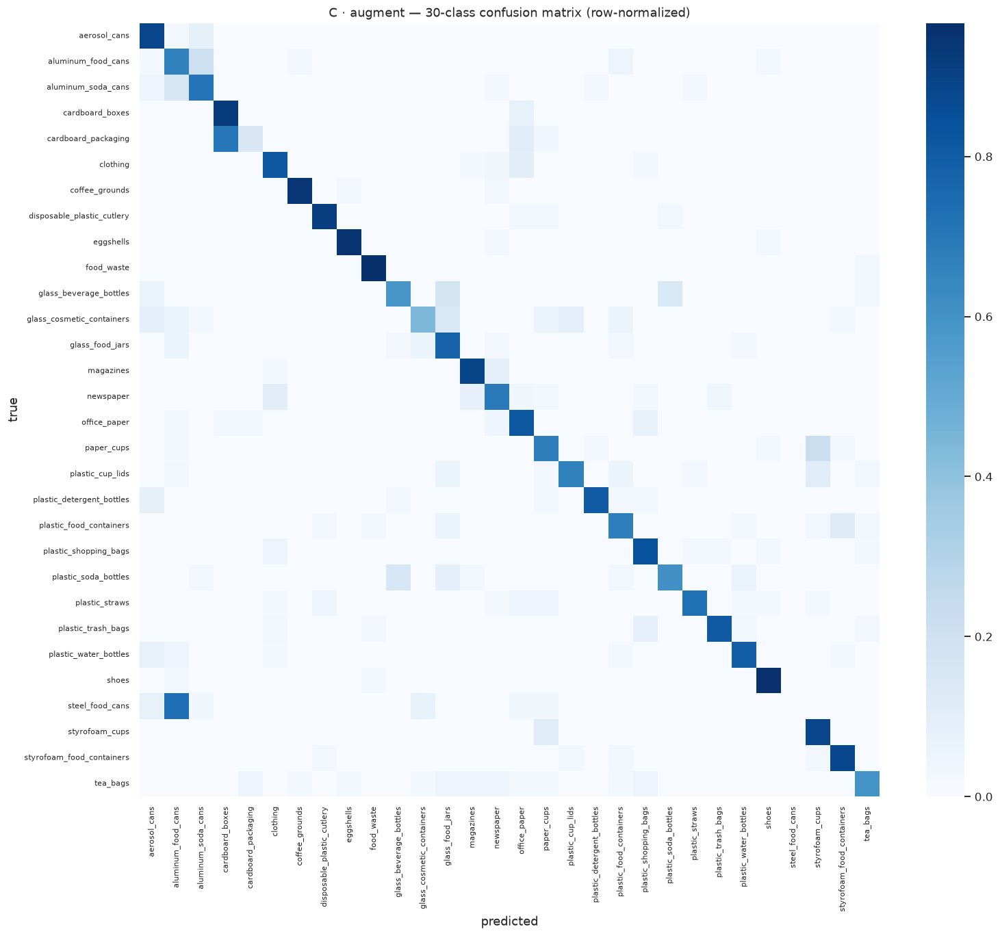

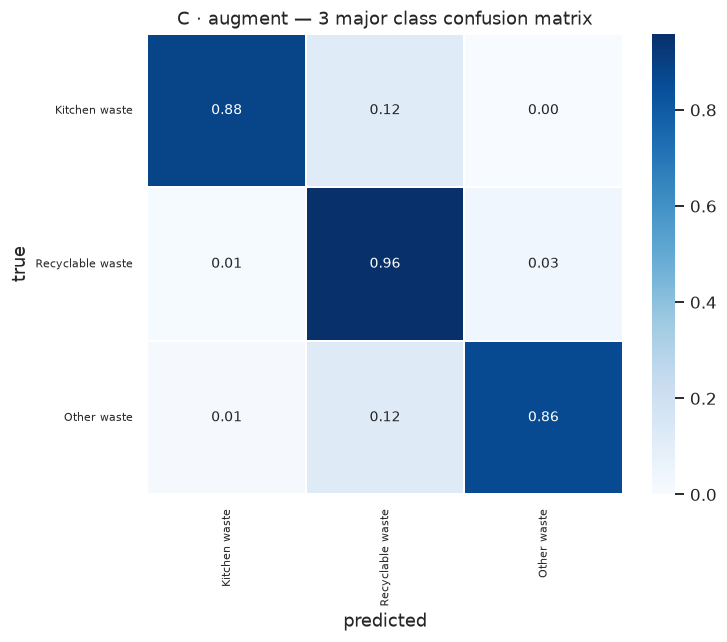

In [15]:
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    label = runs[name]["label"]

    plot_confusion_matrix(
        np.array(metric["confusion_matrix"]),
        CLASS_NAMES,
        f"{label} — 30-class confusion matrix (row-normalized)",
        FIGURE_DIR / f"{name}_confusion_30.png",
        normalize=True,
    )
    plot_confusion_matrix(
        np.array(metric["major_confusion_matrix"]),
        MAJOR_NAMES,
        f"{label} — 3 major class confusion matrix",
        FIGURE_DIR / f"{name}_confusion_major.png",
        normalize=True,
    )

## 10. Analisis error

Semua varian diekspor ke CSV. Gambar contoh hanya dibuat untuk varian dengan test accuracy tertinggi.

Best variant: B · cosine mobilevitxs_cosine
A · baseline: 295 salah dari 1,133 gambar test


,true_class,pred_class,count
0,cardboard_packaging,cardboard_boxes,21
1,steel_food_cans,aluminum_food_cans,17
2,paper_cups,styrofoam_cups,12
3,plastic_food_containers,styrofoam_food_containers,7
4,aluminum_food_cans,aluminum_soda_cans,6


B · cosine: 186 salah dari 1,133 gambar test


,true_class,pred_class,count
0,steel_food_cans,aluminum_food_cans,16
1,cardboard_packaging,cardboard_boxes,8
2,clothing,newspaper,5
3,aluminum_food_cans,aluminum_soda_cans,5
4,plastic_soda_bottles,plastic_water_bottles,5


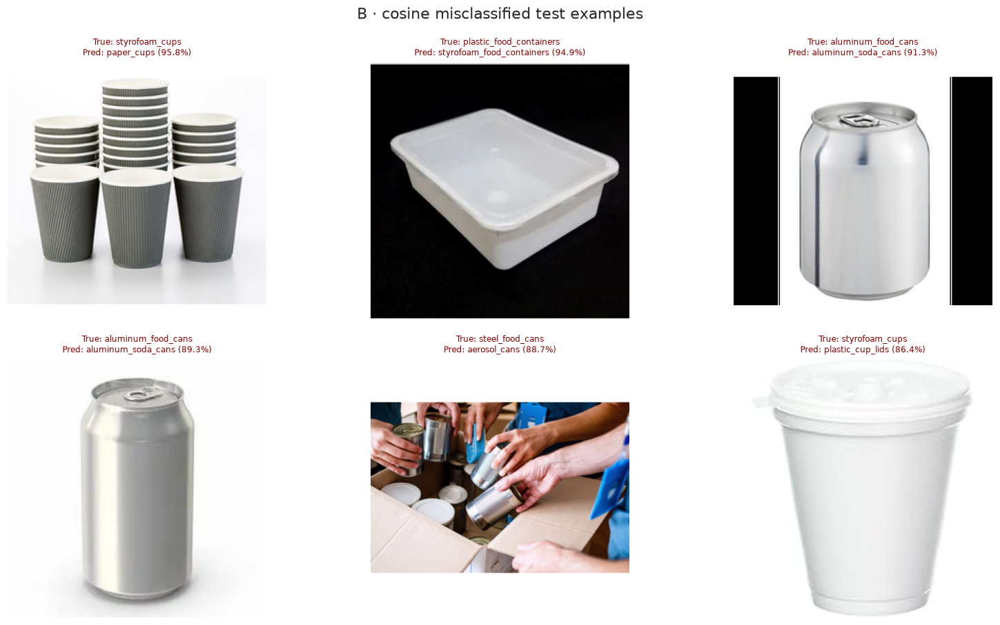

C · augment: 280 salah dari 1,133 gambar test


,true_class,pred_class,count
0,steel_food_cans,aluminum_food_cans,19
1,cardboard_packaging,cardboard_boxes,19
2,paper_cups,styrofoam_cups,9
3,aluminum_food_cans,aluminum_soda_cans,8
4,glass_beverage_bottles,glass_food_jars,6


In [16]:
def build_prediction_frame(frame, probs, labels, preds):
    result = frame[["rel_path", "class_name", "source_group"]].copy()
    result["true_class"] = [CLASS_NAMES[int(i)] for i in labels]
    result["pred_class"] = [CLASS_NAMES[int(i)] for i in preds]
    result["confidence"] = probs.max(axis=1)
    result["correct"] = result["true_class"].eq(result["pred_class"])
    return result


def show_misclassified(predictions, model_name, output_stem, output_path, max_examples=6,
                       make_figure=True):
    errors = (
        predictions[~predictions["correct"]]
        .sort_values("confidence", ascending=False)
        .reset_index(drop=True)
    )
    print(f"{model_name}: {len(errors):,} salah dari {len(predictions):,} gambar test")
    if errors.empty:
        return errors

    errors.to_csv(RESULT_DIR / f"{output_stem}_misclassified.csv", index=False)
    display(
        errors.groupby(["true_class", "pred_class"])
        .size()
        .sort_values(ascending=False)
        .head(5)
        .rename("count")
        .reset_index()
    )

    if not make_figure:
        return errors

    examples = errors.head(max_examples)
    ncols = min(3, len(examples))
    nrows = math.ceil(len(examples) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(DATA_ROOT / row["rel_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f"True: {row['true_class']}\nPred: {row['pred_class']} ({row['confidence'] * 100:.1f}%)",
            fontsize=8,
            color="darkred",
        )
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.suptitle(f"{model_name} misclassified test examples")
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return errors


best_name = max(evaluations, key=lambda k: evaluations[k]["metrics"]["accuracy"])
print("Best variant:", runs[best_name]["label"], best_name)

all_errors = {}
for name, evaluation in evaluations.items():
    predictions = build_prediction_frame(
        test_df, evaluation["probabilities"], evaluation["labels"], evaluation["predictions"]
    )
    all_errors[name] = show_misclassified(
        predictions,
        runs[name]["label"],
        name,
        FIGURE_DIR / f"{name}_misclassified_examples.png",
        make_figure=(name == best_name),
    )

## 11. Perbandingan dengan baseline

Tiga varian MobileViT-XS dari run ini. Kalau `mobilenetv3small_variants_metrics.csv`
sudah ada (hasil notebook MobileNetV3-Small), tiga varian itu ikut dimasukkan. MobileNetV2 dan
CNN dibaca dari `outputs/results/`.

In [17]:
comparison = variant_table.drop(columns=["Prefix"]).copy()
comparison.index = ["V4-Small · " + str(i) for i in comparison.index]
comparison.index.name = "Model"
frames = [comparison]

if (RESULT_DIR / "mobilenetv3large_variants_metrics.csv").exists():
    previous = pd.read_csv(RESULT_DIR / "mobilenetv3large_variants_metrics.csv").set_index("Varian")
    previous.index = ["V3-Large · " + str(i) for i in previous.index]
    previous.index.name = "Model"
    frames.append(previous.drop(columns=["Prefix"], errors="ignore"))
else:
    print("Lewati mobilenetv3large_variants_metrics.csv: belum ada.")
if (RESULT_DIR / "mobilenetv4convs_variants_metrics.csv").exists():
    previous = pd.read_csv(RESULT_DIR / "mobilenetv4convs_variants_metrics.csv").set_index("Varian")
    previous.index = ["V4-Small · " + str(i) for i in previous.index]
    previous.index.name = "Model"
    frames.append(previous.drop(columns=["Prefix"], errors="ignore"))
else:
    print("Lewati mobilenetv4convs_variants_metrics.csv: belum ada.")
if (RESULT_DIR / "mobilenetv3small_variants_metrics.csv").exists():
    previous = pd.read_csv(RESULT_DIR / "mobilenetv3small_variants_metrics.csv").set_index("Varian")
    previous.index = ["V3-Small · " + str(i) for i in previous.index]
    previous.index.name = "Model"
    frames.append(previous.drop(columns=["Prefix"], errors="ignore"))
else:
    print("Lewati mobilenetv3small_variants_metrics.csv: belum ada.")

baseline_path = RESULT_DIR / "model_comparison.csv"
insight_path = RESULT_DIR / "model_insights.csv"
if baseline_path.exists():
    baseline = pd.read_csv(baseline_path).set_index("Model")
    if insight_path.exists():
        extra = pd.read_csv(insight_path).set_index("Model")
        extra = extra.rename(columns={"Macro F1": "Macro F1 (30 kelas)"})
        baseline = baseline.join(extra, how="left")
    frames.append(baseline.reindex(columns=comparison.columns))

comparison = pd.concat(frames)
# shortcut: GMACs MobileNetV2 dari literatur (224 px), CNN tidak diukur di sini.
if "MobileNetV2" in comparison.index:
    comparison.loc["MobileNetV2", "GMACs"] = 0.30

comparison.to_csv(RESULT_DIR / "mobilevitxs_variants_comparison.csv")
display(comparison.round(3))


,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M),GMACs
Model,,,,,,,,,
V4-Small · A · baseline,73.963,0.957,92.586,91.527,90.644,0.710,0.893,1.944,0.772
V4-Small · B · cosine,83.583,0.619,96.028,95.587,95.057,0.820,0.941,1.944,0.772
V4-Small · C · augment,75.287,0.926,92.851,93.027,91.615,0.726,0.910,1.944,0.772
V3-Large · A · baseline,70.962,1.037,87.908,89.585,90.203,0.702,0.861,4.240,0.215
V3-Large · B · cosine,76.434,0.919,89.056,91.703,92.056,0.758,0.888,4.240,0.215
V3-Large · C · augment,72.816,0.999,88.791,89.938,91.086,0.719,0.868,4.240,0.215
V4-Small · A · baseline,49.338,1.827,68.667,77.935,80.583,0.481,0.718,2.531,0.185
V4-Small · B · cosine,68.844,1.144,83.495,88.173,89.232,0.679,0.844,2.531,0.185
V4-Small · C · augment,57.282,1.577,75.552,82.613,84.731,0.564,0.778,2.531,0.185


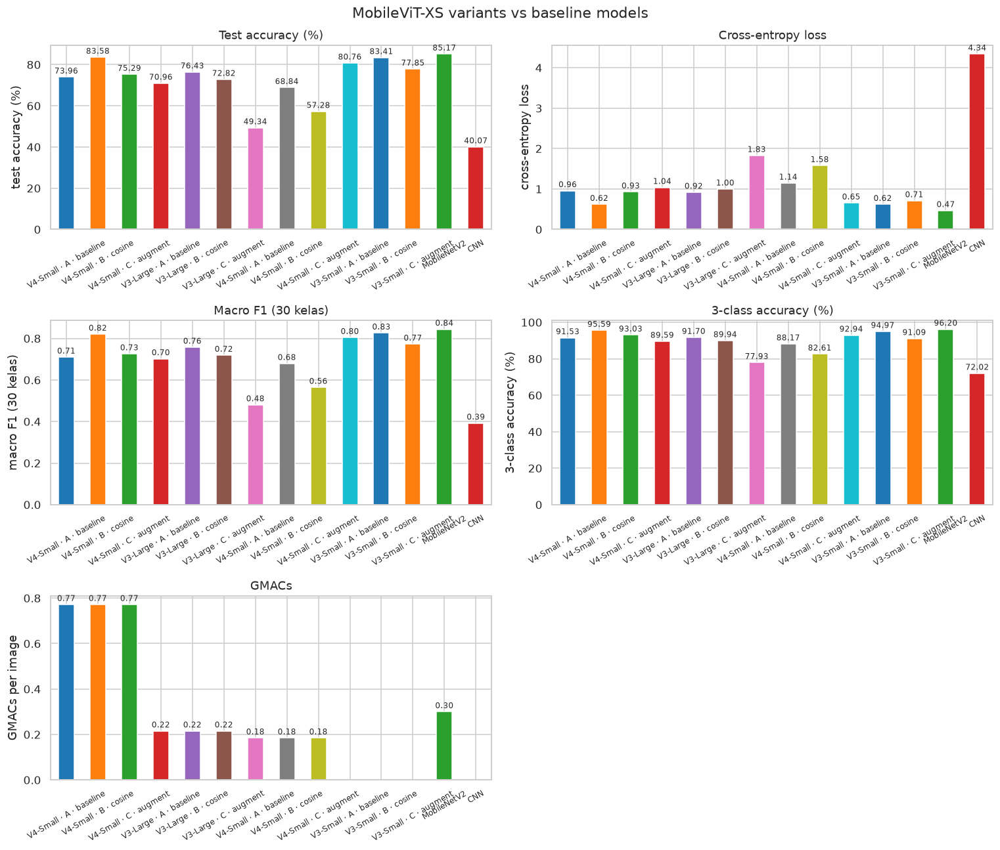

In [18]:
plot_metrics = [
    ("Test accuracy (%)", "test accuracy (%)"),
    ("Cross-entropy loss", "cross-entropy loss"),
    ("Macro F1 (30 kelas)", "macro F1 (30 kelas)"),
    ("3-class accuracy (%)", "3-class accuracy (%)"),
    ("GMACs", "GMACs per image"),
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()
bar_colors = sns.color_palette("tab10", len(comparison))

for ax, (column, ylabel) in zip(axes, plot_metrics):
    values = comparison[column].astype(float)
    values.plot(kind="bar", ax=ax, color=bar_colors)
    ax.set_ylabel(ylabel)
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.set_xlabel("")
    offset = float(values.max()) * 0.02
    for i, value in enumerate(values):
        if pd.notna(value):
            ax.text(i, value + offset, f"{value:.2f}", ha="center", fontsize=8)

for ax in axes[len(plot_metrics):]:
    ax.axis("off")

fig.suptitle("MobileViT-XS variants vs baseline models")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mobilevitxs_variants_comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 12. Simpan ringkasan

In [19]:
variant_records = {}
for name, run in runs.items():
    metric = evaluations[name]["metrics"]
    variant_records[name] = {
        "label": run["label"],
        "config": {
            "scheduler": run["spec"]["scheduler"],
            "label_smoothing": run["spec"]["label_smoothing"],
            "weight_decay": run["spec"]["weight_decay"],
            "augmentation": run["spec"]["augmentation"],
        },
        "best_epoch": int(run["best_epoch"]),
        "best_val_acc": float(run["best_val_acc"]),
        "epochs_run": len(run["history"]),
        "early_stopped": len(run["history"]) < NUM_EPOCHS,
        "parameters": count_parameters(evaluations[name]["model"]),
        "gmacs": float(evaluations[name]["gmacs"]),
        "metrics": {
            "accuracy": metric["accuracy"],
            "loss": metric["loss"],
            "top3_accuracy": metric["top3_accuracy"],
            "major_accuracy": metric["major_accuracy"],
            "major_prob_accuracy": metric["major_prob_accuracy"],
            "macro_f1": metric["macro_f1"],
            "weighted_f1": metric["weighted_f1"],
            "macro_f1_major": metric["major_report"]["macro avg"]["f1-score"],
            "group_accuracy": metric["group_accuracy"],
        },
        "artifacts": {
            "checkpoint": str(run["checkpoint"]),
            "full_model": str(run["full_model"]),
            "history": str(run["history_csv"]),
            "metrics": str(RESULT_DIR / f"{name}_metrics.json"),
        },
    }

summary = {
    "paper": {
        "title": "Application of MobileNetV2 to waste classification",
        "authors": "Yong, Ma, Sun, Du",
        "journal": "PLOS ONE 18(3): e0282336",
        "doi": "10.1371/journal.pone.0282336",
    },
    "arch_paper": {
        "title": "MobileNetV4 - Universal Models for the Mobile Ecosystem",
        "authors": "Qin, Leichner, Delakis, Foronni, Luo, Yang, Wang, Banbury, Ye, Akin, et al.",
        "arxiv": "2404.10518",
        "weights": TIMM_MODEL_NAME,
        "weights_source": "timm",
    },
    "arch": "mobilevit_xs",
    "timm_model": TIMM_MODEL_NAME,
    "pretrained": PRETRAINED,
    "dataset": {
        "root": str(DATA_ROOT),
        "split_manifest": str(SPLIT_MANIFEST),
        "num_classes": NUM_CLASSES,
        "num_images": int(len(df)),
        "split_sizes": {
            split_name: int((df["split"] == split_name).sum())
            for split_name in ("train", "val", "test")
        },
        "major_names": MAJOR_NAMES,
        "class_to_major": CLASS_TO_MAJOR,
    },
    "training": {
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "num_epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "step_size": STEP_SIZE,
        "gamma": GAMMA,
        "test_batch_size": TEST_BATCH_SIZE,
        "early_stopping_patience": EARLY_STOP_PATIENCE,
        "early_stop_min_epochs": EARLY_STOP_MIN_EPOCHS,
        "seed": SEED,
        "device": str(DEVICE),
        "quick_test": QUICK_TEST,
    },
    "variants": variant_records,
    "best_variant": best_name,
    "versions": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "torchvision": __import__("torchvision").__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "timm": getattr(timm, "__version__", "unknown"),
    },
}
with open(RESULT_DIR / "mobilevitxs_variants_summary.json", "w") as handle:
    json.dump(jsonable(summary), handle, indent=2)
print("Wrote", RESULT_DIR / "mobilevitxs_variants_summary.json")

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file() and path.stat().st_mtime >= time.time() - 3600:
        print(f"  {path.relative_to(OUTPUT_DIR)}")

Wrote /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/results/mobilevitxs_variants_summary.json

Output files:
  figures/mobilevitxs_aug_confusion_30.png
  figures/mobilevitxs_aug_confusion_major.png
  figures/mobilevitxs_aug_curves.png
  figures/mobilevitxs_confusion_30.png
  figures/mobilevitxs_confusion_major.png
  figures/mobilevitxs_cosine_confusion_30.png
  figures/mobilevitxs_cosine_confusion_major.png
  figures/mobilevitxs_cosine_curves.png
  figures/mobilevitxs_cosine_misclassified_examples.png
  figures/mobilevitxs_curves.png
  figures/mobilevitxs_variants_comparison.png
  figures/mobilevitxs_variants_curves.png
  models/mobilevitxs_aug_trash30_best.pt
  models/mobilevitxs_aug_trash30_full.pt
  models/mobilevitxs_cosine_trash30_best.pt
  models/mobilevitxs_cosine_trash30_full.pt
  results/mobilevitxs_aug_classification_report.csv
  results/mobilevitxs_aug_history.csv
  results/mobilevitxs_aug_major_report.csv
  results/mobilevitxs_aug_metrics.json
  results/mob

## Catatan

- Arsitektur: MobileViT-XS (`timm` id `mobilevit_xs.cvnets_in1k`), bobot
  ImageNet dari Hugging Face. `timm` dipasang otomatis oleh cell 1.
- Input 224 px (bawaan model 256 px) supaya setara dengan eksperimen lain.
- Bobot pretrained diverifikasi berbeda dari inisialisasi acak sebelum training dimulai.
- Tiga varian berbagi split, seed, transform evaluasi, jumlah epoch, dan early stopping; hanya
  resep training yang berbeda.
- Semua varian diekspor: checkpoint, full model, history CSV, metrics JSON, classification report,
  major report, per-class accuracy, predictions, dan misclassified CSV.
- File MobileNetV2, CNN, MobileNetV3-Small, MobileNetV3-Large, dan MobileNetV4-Conv-Small tidak
  ditimpa.